# Data Preprocessing 

in data processing the raw data is converted into model friendly format to prepare for CNN

leaf image

resize  - sb images ko same size m krna

normalize - to convert the pixel values 0-255 to 0-1

data augmentation - Existing images ke modified versions banana—jaise rotation, flipping, zoom—taaki model different orientations me leaves ko recognize kar sake.

train/validation/test split - Train: model learn krna h.
Validation: training ke during model ko check krna h.
Test: final performance check krna h.

dataset is ready for CNN


In [27]:
import tensorflow as tf   #for deep learning model and dataset pipeline
import os   #to handle the dataset path
import matplotlib.pyplot as plt #to visualize the image

In [28]:
dataset_path = r"D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village"
print(dataset_path)

D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village


In [29]:
IMG_SIZE = (256,256) # Resize images to 256x256 pixels

In [30]:
BATCH_SIZE = 32 # no of images to process in a batch

#  to divide dataset into three parts = 
train - 80%

validation - 10%

test - 10%

In [31]:
# to load training dataset

train_dataset = tf.keras.utils.image_dataset_from_directory(  #function to load images from directory and create a tensorflow dataset with llabels
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 50500 files belonging to 36 classes.
Using 40400 files for training.


In [32]:
# validation dataset  


validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)



Found 50500 files belonging to 36 classes.
Using 10100 files for validation.


## difference between training and validation data?



"Training data is used by the model to learn patterns, while validation data is used during training to monitor how well the model performs on data that it has not directly trained on."

In [33]:
val_batches = tf.data.experimental.cardinality(validation_dataset)

print("Validation batches:", val_batches.numpy())

Validation batches: 316


In [34]:
test_dataset = validation_dataset.take(val_batches // 2)
validation_dataset = validation_dataset.skip(val_batches // 2)

In [35]:
print("Train batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Train batches: 1263
Validation batches: 158
Test batches: 158


# Normalize the image


to convert pixel value 0-255 to 0-1

In [36]:
normalization_layer = tf.keras.layers.Rescaling(1./255)  #means we are scaling the pixel values from 0-255 to 0-1  1. means pixel/255

In [37]:
#applied on the trained dataset
train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [38]:
validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [39]:
test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

# Note 

normalization train , validation ayr test teeno pr hogi but augmentation only train dataset pr hogi

In [40]:
for images, labels in train_dataset.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [41]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(256, 256, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [44]:
for images, labels in train_dataset.take(1):
    augmented_images = data_augmentation(images)
    print("Original shape:", images.shape)
    print("Augmented shape:", augmented_images.shape)

Original shape: (32, 256, 256, 3)
Augmented shape: (32, 256, 256, 3)


In [45]:
for images, labels in train_dataset.take(1):
    sample_image = images[0]
    sample_label = labels[0]
    break

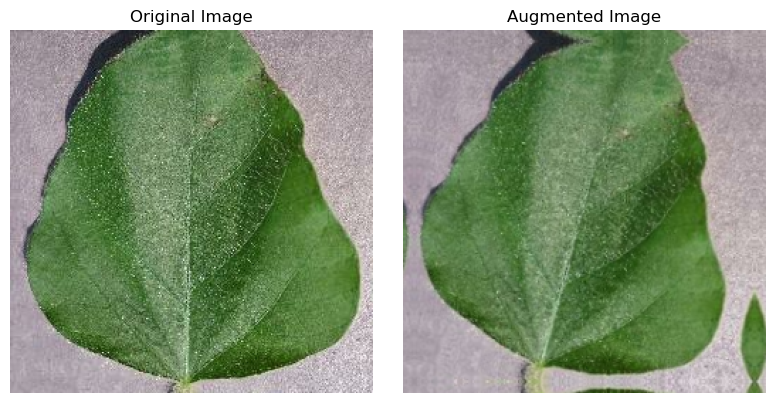

In [57]:
# comparison between original image and augmented image

# sample test
import numpy as np

sample_image_batch = tf.expand_dims(sample_image, axis=0)

augmented_image_batch = data_augmentation(sample_image_batch)

augmented_image = augmented_image_batch[0]

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image)
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# use of data augmentation 

Data augmentation creates different variations of training images, such as flipping, rotation and zooming. This helps the model generalize better to real-world images and reduces over-dependence on the exact training images.

In [50]:
train_dataset = train_dataset.map(
    lambda x, y: (data_augmentation(x), y)
)

In [51]:
for images, labels in train_dataset.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Images shape: (32, 256, 256, 3)
Labels shape: (32,)


# Logic of pipeline 

                PlantVillage
                     ↓
              Train / Val / Test
                     ↓
              80% / 10% / 10%
                     ↓
       ┌─────────────┼─────────────┐
       ↓             ↓             ↓
     Train         Validation      Test
       ↓             ↓             ↓
 Normalization   Normalization  Normalization
       ↓
 Augmentation
       ↓
    CNN Model

In [52]:
# prefetching the dataset to improve performance

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)


# final verification

In [53]:
for images, labels in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image shape: (32, 256, 256, 3)
Label shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 0.9999849


In [58]:
classes = os.listdir(dataset_path)

In [59]:
print("Number of classes:", len(classes))
print("Classes:")
for i, class_name in enumerate(classes):
    print(i, ":", class_name)

Number of classes: 36
Classes:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___healthy
6 : Cherry_(including_sour)___Powdery_mildew
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___healthy
10 : Corn_(maize)___Northern_Leaf_Blight
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___healthy
14 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___healthy
22 : Potato___Late_blight
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___healthy
27 : Strawberry___Leaf_scorch
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_blight
31 : Tomato___Leaf_Mold
32 : Tomato___S

##  Observations

- The PlantVillage dataset was divided into training, validation, and testing datasets.
- The images were resized to 256 × 256 pixels.
- The dataset contains RGB images with 3 color channels.
- Pixel values were normalized from the 0–255 range to approximately 0–1.
- Data augmentation techniques such as horizontal flipping, rotation, and zooming were applied to the training dataset.
- Validation and test datasets were kept free from data augmentation.
- The class labels were successfully identified from the dataset folders.
- The final training pipeline was optimized using TensorFlow prefetching.

##  Conclusion

The PlantVillage dataset has been successfully preprocessed and prepared for model development. The data is divided into training, validation, and testing sets, and the images have been resized and normalized. Data augmentation was applied only to the training data to improve the model's ability to handle variations in real-world images. The processed dataset is now ready for building and training the plant disease detection model.

# Workflow 

             PlantVillage
                  │
                  ▼
          Dataset Loading
                  │
                  ▼
          Train / Val / Test
           80% / 10% / 10%
                  │
          ┌───────┴────────┐
          │                │
       Training       Val + Test
          │                │
    Normalization      Normalization
          │                │
     Augmentation          │
          │                │
       Prefetch         Prefetch
          │                │
          └───────┬────────┘
                  ▼
             READY FOR
            CNN MODEL 🌱